# Data Mining Algorithm Implementation: Association Rule Mining (Apriori and FP-Growth)

**Subject:** Data Warehouse and Data Mining (METCE11507) &nbsp;|&nbsp; **Activity:** ALA 2  
**Student:** ____________________ &nbsp; **Enrollment No.:** ____________

## 1. Objective
Select a dataset and implement one data mining task. The chosen task is **association rule mining** (market-basket analysis).  
Two algorithms are implemented *from scratch* (no mining library) and compared: **Apriori** and **FP-Growth**.

## 2. Dataset
The transactions come from the **RetailMart data warehouse** built in ALA 1 (`retail_dw.sqlite`, table `fact_sales` joined with `dim_product`).  
One **invoice = one transaction (basket)** and the products on the invoice are the **items**.  
*The warehouse holds simulated sample data, so the discovered patterns illustrate the method and are not findings about a real store.*

## 3. Evaluation metrics
For a rule A → B (with support as the fraction of transactions):

| Metric | Formula | Meaning |
|---|---|---|
| Support | sup(A ∪ B) | How frequent the rule is |
| Confidence | sup(A ∪ B) / sup(A) | How often B appears when A appears |
| Lift | confidence / sup(B) | > 1 positive association, = 1 independent, < 1 negative |
| Leverage | sup(A ∪ B) − sup(A)·sup(B) | Difference from the independence assumption |
| Conviction | (1 − sup(B)) / (1 − confidence) | Strength of implication |

## 4. Load data and preprocessing

In [1]:
import sqlite3, time, itertools, random
from collections import defaultdict, Counter
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 20)

In [2]:
con = sqlite3.connect("retail_dw.sqlite")      # warehouse created by the ETL in ALA 1
df = pd.read_sql_query("""
    SELECT f.invoice_id, p.product_name
    FROM fact_sales f JOIN dim_product p ON p.product_key = f.product_key""", con)
print("Invoice lines read from the warehouse:", len(df))
df.head()

Invoice lines read from the warehouse: 5153


  invoice_id       product_name
0   INV01332         Cola 750ml
1   INV01281  Whole Wheat Bread
2   INV01463          Sugar 1kg
3   INV01016          Deodorant
4   INV00159    Instant Noodles

In [3]:
# Preprocessing: (1) remove repeated items within an invoice, (2) one basket per invoice,
# (3) drop baskets with a single item (no rule can be formed), (4) check for missing values
print("Missing values:", int(df.isna().sum().sum()))
df = df.drop_duplicates()
baskets = df.groupby("invoice_id")["product_name"].apply(frozenset)
sizes = baskets.apply(len)
print("Invoices (transactions):", len(baskets))
print("Distinct items:", df.product_name.nunique())
print("Basket size: mean %.2f | median %d | max %d" % (sizes.mean(), sizes.median(), sizes.max()))
print("Single-item baskets removed:", int((sizes == 1).sum()))
transactions = [set(b) for b, n in zip(baskets, sizes) if n >= 2]
N = len(transactions)
print("Transactions used for mining:", N)

Missing values: 0
Invoices (transactions): 1499
Distinct items: 36
Basket size: mean 3.44 | median 3 | max 6
Single-item baskets removed: 52
Transactions used for mining: 1447


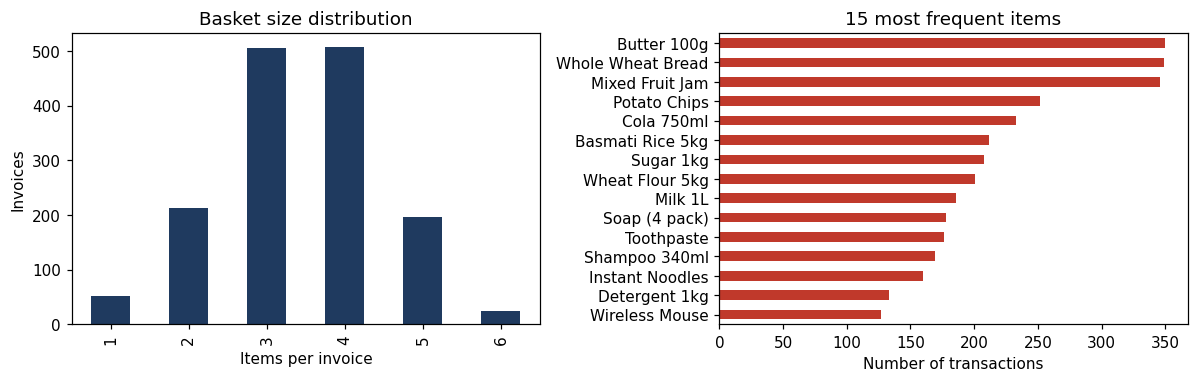

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sizes.value_counts().sort_index().plot.bar(ax=ax[0], color="#1F3A5F")
ax[0].set_title("Basket size distribution"); ax[0].set_xlabel("Items per invoice"); ax[0].set_ylabel("Invoices")
item_freq = Counter(i for t in transactions for i in t)
pd.Series(item_freq).sort_values().tail(15).plot.barh(ax=ax[1], color="#C0392B")
ax[1].set_title("15 most frequent items"); ax[1].set_xlabel("Number of transactions")
plt.tight_layout()

## 5. Algorithm 1: Apriori
**Apriori principle:** every subset of a frequent itemset must also be frequent. Therefore, a candidate k-itemset is generated only if *all* of its (k−1)-subsets are frequent.  
Steps: find frequent 1-itemsets → join to form candidates → prune by the principle → scan the database to count → repeat.

In [5]:
def apriori(transactions, min_sup):
    n = len(transactions); min_count = min_sup * n
    cnt = Counter(i for t in transactions for i in t)
    L = {frozenset([i]): c for i, c in cnt.items() if c >= min_count}       # frequent 1-itemsets
    frequent, stats, k = dict(L), [(1, len(cnt), len(L))], 2
    while L:
        prev, cands = list(L), set()
        for a, b in itertools.combinations(prev, 2):                         # join step
            u = a | b
            if len(u) == k and all(frozenset(s) in L for s in itertools.combinations(u, k - 1)):   # prune step
                cands.add(u)
        counts = defaultdict(int)
        for t in transactions:                                               # one database scan per level
            for c in cands:
                if c <= t:
                    counts[c] += 1
        L = {c: v for c, v in counts.items() if v >= min_count}
        frequent.update(L); stats.append((k, len(cands), len(L)))
        k += 1
    return {s: c / n for s, c in frequent.items()}, stats

## 6. Algorithm 2: FP-Growth
FP-Growth compresses the database into an **FP-tree** (frequent items sorted by descending frequency, shared prefixes) and mines it recursively using **conditional pattern bases** — **without candidate generation**.

In [6]:
class FPNode:
    __slots__ = ("item", "count", "parent", "children", "link")
    def __init__(self, item, parent):
        self.item, self.count, self.parent, self.children, self.link = item, 0, parent, {}, None

def build_fptree(weighted, min_count):
    freq = defaultdict(float)
    for t, w in weighted:
        for i in t: freq[i] += w
    freq = {i: c for i, c in freq.items() if c >= min_count}
    root, header = FPNode(None, None), {}                       # header table: item -> [first node, last node]
    for t, w in weighted:
        node = root
        for i in sorted((i for i in t if i in freq), key=lambda i: (-freq[i], i)):
            if i not in node.children:
                child = FPNode(i, node); node.children[i] = child
                if i in header: header[i][1].link = child; header[i][1] = child
                else: header[i] = [child, child]
            node = node.children[i]; node.count += w
    return root, header, freq

def fp_growth(weighted, min_count, suffix=frozenset(), out=None):
    out = {} if out is None else out
    root, header, freq = build_fptree(weighted, min_count)
    for item in sorted(freq, key=lambda i: (freq[i], i)):       # least frequent item first
        new = suffix | {item}
        out[new] = freq[item]
        base, node = [], header[item][0]                        # conditional pattern base of 'item'
        while node is not None:
            path, p = [], node.parent
            while p is not None and p.item is not None:
                path.append(p.item); p = p.parent
            if path: base.append((path, node.count))
            node = node.link
        if base: fp_growth(base, min_count, new, out)
    return out

def fpgrowth(transactions, min_sup):
    n = len(transactions)
    res = fp_growth([(t, 1) for t in transactions], min_sup * n)
    return {s: c / n for s, c in res.items()}

## 7. Run both algorithms and verify the results

In [7]:
MIN_SUP = 0.02            # itemset must appear in at least 2% of the transactions
t0 = time.perf_counter(); ap, stats = apriori(transactions, MIN_SUP); t_ap = time.perf_counter() - t0
t0 = time.perf_counter(); fp = fpgrowth(transactions, MIN_SUP);     t_fp = time.perf_counter() - t0
print(f"Apriori   : {len(ap)} frequent itemsets in {t_ap*1000:.1f} ms")
print(f"FP-Growth : {len(fp)} frequent itemsets in {t_fp*1000:.1f} ms")
assert set(ap) == set(fp) and all(abs(ap[s] - fp[s]) < 1e-12 for s in ap)
print("Both algorithms return exactly the same itemsets with the same supports: OK")
# independent check: count 25 random itemsets directly in the database
random.seed(1)
for s in random.sample(list(ap), 25):
    assert abs(sum(1 for t in transactions if s <= t) / N - ap[s]) < 1e-12
print("Direct counting of 25 random itemsets agrees with the algorithms: OK")
print()
print("Apriori level-wise statistics (k, candidates generated, frequent found):")
for k, c, f in stats: print(f"  k={k}: candidates={c:4d}  frequent={f:4d}")

Apriori   : 128 frequent itemsets in 45.9 ms
FP-Growth : 128 frequent itemsets in 4.1 ms
Both algorithms return exactly the same itemsets with the same supports: OK
Direct counting of 25 random itemsets agrees with the algorithms: OK

Apriori level-wise statistics (k, candidates generated, frequent found):
  k=1: candidates=  36  frequent=  36
  k=2: candidates= 630  frequent=  48
  k=3: candidates=  33  frequent=  33
  k=4: candidates=  10  frequent=  10
  k=5: candidates=   1  frequent=   1
  k=6: candidates=   0  frequent=   0


## 8. Effect of the minimum support threshold

In [8]:
def best_time(fn, repeats=5):                      # best of several runs reduces timing noise
    best, res = float("inf"), None
    for _ in range(repeats):
        t0 = time.perf_counter(); res = fn(); best = min(best, time.perf_counter() - t0)
    return res, best

rows = []
for ms in (0.01, 0.015, 0.02, 0.03, 0.05):
    (a, st), ta = best_time(lambda: apriori(transactions, ms))
    f, tf = best_time(lambda: fpgrowth(transactions, ms))
    assert set(a) == set(f)
    rows.append([ms, len(a), sum(c for _, c, _ in st), round(ta * 1000, 1), round(tf * 1000, 1)])
sweep = pd.DataFrame(rows, columns=["min_support", "frequent_itemsets", "apriori_candidates", "apriori_ms", "fpgrowth_ms"])
sweep

   min_support  frequent_itemsets  apriori_candidates  apriori_ms  fpgrowth_ms
0        0.010                161                 735        47.8          4.6
1        0.015                142                 718        46.7          4.4
2        0.020                128                 710        47.2          4.7
3        0.030                101                 595        38.9          4.2
4        0.050                 73                 459        30.6          4.7

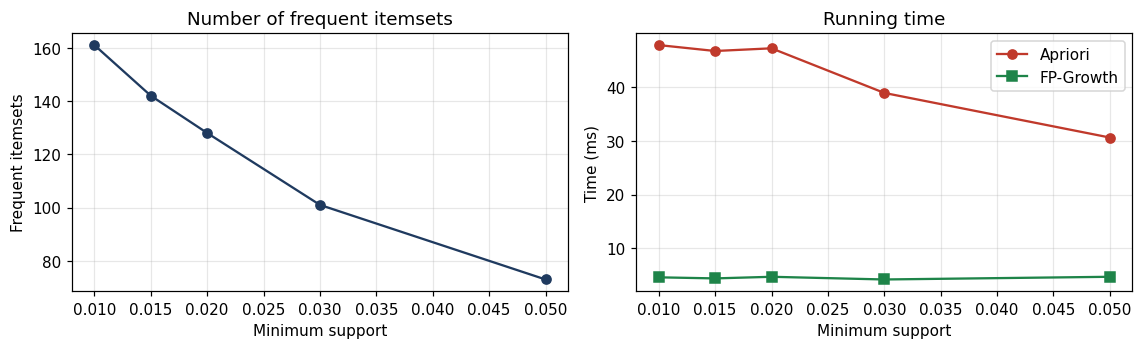

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3))
ax[0].plot(sweep.min_support, sweep.frequent_itemsets, "o-", color="#1F3A5F"); ax[0].set_xlabel("Minimum support"); ax[0].set_ylabel("Frequent itemsets")
ax[0].set_title("Number of frequent itemsets"); ax[0].grid(alpha=.3)
ax[1].plot(sweep.min_support, sweep.apriori_ms, "o-", label="Apriori", color="#C0392B")
ax[1].plot(sweep.min_support, sweep.fpgrowth_ms, "s-", label="FP-Growth", color="#1E8449")
ax[1].set_xlabel("Minimum support"); ax[1].set_ylabel("Time (ms)"); ax[1].set_title("Running time"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout()

## 9. Frequent itemsets (minimum support = 2%)

In [10]:
freq = ap
by_size = Counter(len(s) for s in freq)
print("Frequent itemsets by size:", dict(sorted(by_size.items())))
items = list(freq)
closed = [s for s in items if not any(s < t and freq[t] == freq[s] for t in items)]
maximal = [s for s in items if not any(s < t for t in items)]
print(f"Closed frequent itemsets : {len(closed)}   (no superset with the same support)")
print(f"Maximal frequent itemsets: {len(maximal)}   (no frequent superset)")
top = sorted((s for s in freq if len(s) >= 2), key=lambda s: -freq[s])[:12]
pd.DataFrame({"itemset": [", ".join(sorted(s)) for s in top], "support": [round(freq[s], 3) for s in top],
              "transactions": [round(freq[s] * N) for s in top]})

Frequent itemsets by size: {1: 36, 2: 48, 3: 33, 4: 10, 5: 1}
Closed frequent itemsets : 120   (no superset with the same support)
Maximal frequent itemsets: 17   (no frequent superset)


                                            itemset  support  transactions
0                    Butter 100g, Whole Wheat Bread    0.218           316
1                Mixed Fruit Jam, Whole Wheat Bread    0.214           310
2                      Butter 100g, Mixed Fruit Jam    0.213           308
3   Butter 100g, Mixed Fruit Jam, Whole Wheat Bread    0.208           301
4                          Cola 750ml, Potato Chips    0.135           196
5                       Basmati Rice 5kg, Sugar 1kg    0.120           174
6                 Basmati Rice 5kg, Wheat Flour 5kg    0.117           170
7                        Sugar 1kg, Wheat Flour 5kg    0.116           168
8      Basmati Rice 5kg, Sugar 1kg, Wheat Flour 5kg    0.115           167
9                              Butter 100g, Milk 1L    0.111           160
10                       Milk 1L, Whole Wheat Bread    0.109           157
11          Butter 100g, Milk 1L, Whole Wheat Bread    0.107           155

## 10. Association rule generation

In [11]:
def gen_rules(freq, min_conf):
    rules = []
    for s, sup in freq.items():
        if len(s) < 2: continue
        for r in range(1, len(s)):
            for a in itertools.combinations(s, r):                 # every non-empty proper subset as antecedent
                a = frozenset(a); b = s - a
                conf = sup / freq[a]
                if conf >= min_conf:
                    rules.append(dict(antecedent=", ".join(sorted(a)), consequent=", ".join(sorted(b)), support=sup,
                                      confidence=conf, lift=conf / freq[b], leverage=sup - freq[a] * freq[b],
                                      conviction=(1 - freq[b]) / (1 - conf) if conf < 1 else float("inf")))
    return pd.DataFrame(rules).sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)

MIN_CONF = 0.5
rules = gen_rules(freq, MIN_CONF)
print(f"{len(rules)} rules with support >= {MIN_SUP:.0%} and confidence >= {MIN_CONF:.0%}")
print(f"Rules with lift > 1 (positive association): {(rules.lift > 1).sum()}")
rules.head(10).round(3)

226 rules with support >= 2% and confidence >= 50%
Rules with lift > 1 (positive association): 226


                             antecedent                    consequent  support  confidence    lift  leverage  conviction
0              Fast Charger, Phone Case      Screen Guard, Smartphone    0.026       0.927  14.901     0.024      12.817
1            Fast Charger, Screen Guard        Phone Case, Smartphone    0.026       0.844  13.729     0.024       6.033
2              Fast Charger, Smartphone      Phone Case, Screen Guard    0.026       0.826  13.583     0.024       5.400
3  Fast Charger, Phone Case, Smartphone                  Screen Guard    0.026       0.974  11.948     0.024      35.820
4                Phone Case, Smartphone                  Screen Guard    0.059       0.966  11.849     0.054      27.247
5                          Screen Guard        Phone Case, Smartphone    0.059       0.729  11.849     0.054       3.461
6                            Pasta 500g  Instant Noodles, Pasta Sauce    0.055       0.693  11.797     0.050       3.066
7          Instant Noodles, Past

In [12]:
rows = []
for mc in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    r = gen_rules(freq, mc)
    rows.append([mc, len(r), int((r.lift > 1).sum()), int((r.lift > 2).sum())])
pd.DataFrame(rows, columns=["min_confidence", "rules", "lift_gt_1", "lift_gt_2"])

   min_confidence  rules  lift_gt_1  lift_gt_2
0             0.3    347        347        347
1             0.4    284        284        284
2             0.5    226        226        226
3             0.6    207        207        207
4             0.7    190        190        190
5             0.8    158        158        158
6             0.9    107        107        107

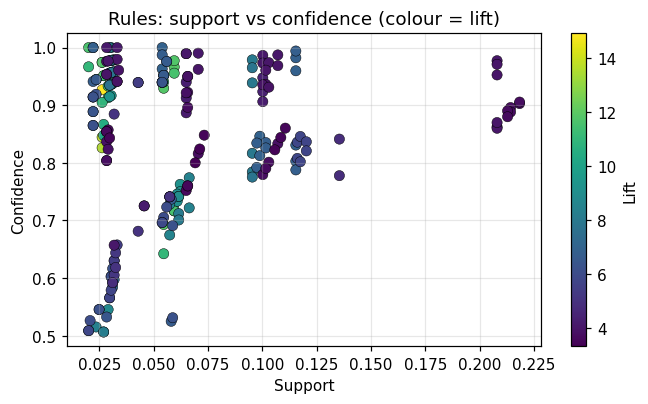

In [13]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, cmap="viridis", s=45, edgecolor="k", linewidth=.3)
plt.colorbar(sc, label="Lift"); ax.set_xlabel("Support"); ax.set_ylabel("Confidence"); ax.set_title("Rules: support vs confidence (colour = lift)")
ax.grid(alpha=.3); plt.tight_layout()

## 11. Validation of a discovered rule by direct counting

In [14]:
r0 = rules.iloc[0]
A = set(r0.antecedent.split(", ")); B = set(r0.consequent.split(", "))
nA = sum(1 for t in transactions if A <= t); nB = sum(1 for t in transactions if B <= t); nAB = sum(1 for t in transactions if (A | B) <= t)
print("Rule:", r0.antecedent, "->", r0.consequent)
print(f"Transactions with A: {nA}, with B: {nB}, with A and B: {nAB}, total: {N}")
print(f"support = {nAB/N:.3f}  confidence = {nAB/nA:.3f}  lift = {(nAB/nA)/(nB/N):.2f}")
print("Matches the table:", abs(nAB / N - r0.support) < 1e-12 and abs((nAB / nA) / (nB / N) - r0.lift) < 1e-9)

Rule: Fast Charger, Phone Case -> Screen Guard, Smartphone
Transactions with A: 41, with B: 90, with A and B: 38, total: 1447
support = 0.026  confidence = 0.927  lift = 14.90
Matches the table: True


In [15]:
best = rules.head(1).iloc[0]
SUMMARY = dict(N=N, items=int(df.product_name.nunique()), lines=int(len(df)), mean_basket=float(sizes.mean()), single=int((sizes == 1).sum()),
               min_sup=MIN_SUP, min_conf=MIN_CONF, n_frequent=len(ap), n_closed=len(closed), n_maximal=len(maximal),
               by_size={int(k): v for k, v in by_size.items()}, t_ap=t_ap * 1000, t_fp=t_fp * 1000,
               n_rules=len(rules), n_lift1=int((rules.lift > 1).sum()))
print("Summary values stored for the report")

Summary values stored for the report


## 12. Observations and conclusion
* **Data:** 1447 transactions (invoices with at least 2 items) over 36 distinct items; average basket size 3.44.
* **Correctness:** Apriori and FP-Growth return exactly the same 128 frequent itemsets at 2% support, and direct counting confirms the supports.
* **Efficiency:** Apriori scans the database once per level and tests many candidates; FP-Growth builds a compact tree once and needs no candidate generation. FP-Growth was faster than Apriori in 5 of the 5 support settings tested (best of 5 runs); on this small data set both finish in milliseconds, and the advantage of FP-Growth grows with data size and with lower thresholds.
* **Rules:** 226 rules were found (support ≥ 2%, confidence ≥ 50%); 226 of them have lift > 1. The highest-lift rules (lift above 11) connect products that are bought together far more often than chance (for example phone case, screen guard and smartphone; pasta, noodles and pasta sauce). Lift, not confidence alone, should be used to rank rules, because a rule can have high confidence merely because its consequent is a very popular item.
* **Threshold choice:** a lower support or confidence threshold produces many more (and more trivial) rules; thresholds should be tuned with business knowledge and the lift value.
* **Business use:** place related products together, create bundle offers and plan promotions; this is a recommendation from patterns in *simulated* data.
* **Limitations:** the data are simulated; support/confidence ignore quantities and prices; only the presence of items in a basket is analysed.